<a href="https://colab.research.google.com/github/yihan4326/MSSP607/blob/main/WeeklyModules/Week07/participation_week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

# Go to the main Colab directory
os.chdir('/content')

# Get GitHub token from Colab Secrets
github_token = userdata.get('Git_Hub')

# Set the repository owner and name
owner = 'yihan4326'
repository = 'MSSP607'

# Create the clone URL
clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

# Clone the repository if it does not already exist
if not os.path.exists(repository):
    subprocess.run(['git', 'clone', clone_url], check=True)

# Change directory to the repository
os.chdir(repository)

print(f"Changed directory to: {os.getcwd()}")

Changed directory to: /content/MSSP607


In [2]:
# Read the Internet Sales dataset
df = pd.read_csv('data/InternetSales.csv', encoding='cp1252',
                 low_memory=False)

# Check the size of the dataset
print("Data shape:", df.shape)

# Display the first five rows
df.head()

Data shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


In [3]:
# Convert OrderDate to datetime format
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

# Create a new column for year
df['Year'] = df['OrderDate'].dt.year

# Calculate total sales for each year
yearly_sales = df.groupby('Year')['SalesAmount'].sum()

# Display yearly sales
print(yearly_sales)

Year
2010    4.342104e+04
2011    7.075526e+06
2012    5.842485e+06
2013    1.635155e+07
2014    4.569472e+04
Name: SalesAmount, dtype: float64


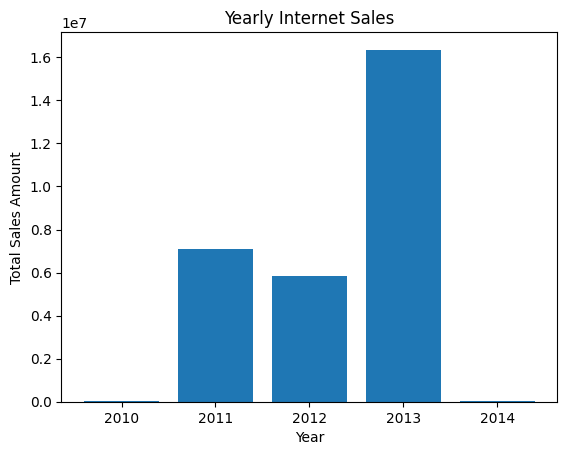

In [4]:
# Create a bar chart
plt.bar(yearly_sales.index, yearly_sales.values)

# Add chart title and labels
plt.title('Yearly Internet Sales')
plt.xlabel('Year')
plt.ylabel('Total Sales Amount')

# Display each year on the x-axis
plt.xticks(yearly_sales.index)

# Save the active figure as a PDF
plt.savefig('yearly_sales.pdf', bbox_inches='tight')

# Display the chart
plt.show()